# 01 — Análise Exploratória (EDA) · Prevenção a Fraudes em Cartões · Sicredi

**Objetivo:** entender a base de transações de cartões e decidir, coluna a coluna, o que entra na base de modelagem.

Cada seção termina com uma **decisão** (manter, remover, transformar ou investigar). No fim, a seção 13 consolida essas decisões numa tabela de triagem, que alimenta o próximo notebook (limpeza e geração da base de modelagem).

| # | Seção | Pergunta que responde |
|---|---|---|
| 1 | Setup e carga | A base está completa? |
| 2 | Dicionário de dados | O que significa cada grupo de colunas? |
| 3 | Estrutura | Quais são os tipos, a cardinalidade, as constantes e as duplicatas? |
| 4 | Qualidade: nulos | Onde faltam dados? A ausência diz algo sobre fraude? |
| 5 | Qualidade: valores inválidos | Há valores impossíveis ou inconsistentes? |
| 6 | Variável alvo | Quanto de fraude há, e onde? |
| 7 | Análise temporal | Quando as fraudes acontecem? Como dividir treino e teste? |
| 8 | Categóricas × fraude | Quais categorias concentram fraude? |
| 9 | Numéricas × fraude | Quais variáveis separam fraude de legítima? |
| 10 | Vazamento (leakage) | Quais colunas "entregam" a resposta? |
| 11 | Entidades e velocidade | Cartões, clientes e devices se repetem? Há rajadas? |
| 12 | Geografia | A divergência de localização é sinal? |
| 13 | Triagem de colunas | O que vai para a base de modelagem? |
| 14 | Conclusões | Resumo e próximos passos |

> Todos os registros são **sintéticos** (ver `data/Orientacoes_case_prevencao_sicredi.txt`).

## 1. Setup e carga

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from scipy.stats import chi2_contingency, norm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 200)

# Caminhos: o notebook roda a partir de notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
CSV = DATA / "case_transacoes_cartoes_sintetico_900k.csv"
DICIONARIO = DATA / "dicionario_dados_case_prevencao_sicredi.xlsx"
CACHE = DATA / "transacoes.pkl"          # cache local (ignorado pelo git)
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

# Paleta (dataviz default, validada para daltonismo): azul = legítima, laranja = fraude
COR_LEGIT, COR_FRAUDE, COR_NEUTRA = "#2a78d6", "#eb6834", "#8a8a85"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "grid.color": "#e6e6e3", "axes.edgecolor": "#b5b5af"})
plt.rcParams["figure.dpi"] = 110

In [2]:
if CACHE.exists() and CACHE.stat().st_mtime > CSV.stat().st_mtime:
    df = pd.read_pickle(CACHE)
else:
    df = pd.read_csv(CSV, low_memory=False)
    df.to_pickle(CACHE)

ALVO = "feedback_label"
df[ALVO] = df[ALVO].astype(str).str.lower().map({"true": True, "false": False})
y = df[ALVO]

print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]} | Memória: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")
print(f"Fraudes: {y.sum():,} ({y.mean():.3%})")

Linhas: 160,000 | Colunas: 297 | Memória: 1.65 GB
Fraudes: 146 (0.091%)


**Checagem de completude:** as orientações do case descrevem **900.000 linhas e 900 fraudes (0,10%)**. Se o número acima for diferente, o arquivo baixado está incompleto (por exemplo, um download ou descompactação parcial do `.csv.gz`). A taxa de fraude, porém, deve ficar perto de 0,1% em qualquer recorte.

In [3]:
ESPERADO_LINHAS = 900_000
if len(df) != ESPERADO_LINHAS:
    print(f"⚠️  Base com {len(df):,} linhas; o case descreve {ESPERADO_LINHAS:,}. "
          f"Último ID de evento: {df['event_external_id'].dropna().iloc[-1] if 'event_external_id' in df else 'n/d'}")
else:
    print("✅ Base completa.")

⚠️  Base com 160,000 linhas; o case descreve 900,000. Último ID de evento: EVT_SYN_000159999


## 2. Dicionário de dados

In [4]:
dic = pd.read_excel(DICIONARIO)
dic.columns = ["coluna", "categoria", "tipo_sugerido", "descricao", "observacao"]
grupo = dic.set_index("coluna")["categoria"]

print("Colunas no CSV que não estão no dicionário:", sorted(set(df.columns) - set(dic.coluna)))
print("Colunas no dicionário que não estão no CSV:", sorted(set(dic.coluna) - set(df.columns)))
dic.groupby("categoria").size().sort_values(ascending=False).rename("n_colunas").to_frame()

Colunas no CSV que não estão no dicionário: []
Colunas no dicionário que não estão no CSV: []


,n_colunas
categoria,
evento/modelo,121
cliente,51
dispositivo/terminal,36
conta,33
cartão,28
estabelecimento,23
transação,4
alvo,1


O dicionário é genérico: quase todas as descrições dizem *"Campo sintético inspirado no nome técnico..."*. Por isso o significado de cada coluna precisa ser **inferido pelo nome e confirmado pelos dados**. Só quatro colunas têm descrição própria: `cp_card_term_vel_1h`, `cp_card_prev_term_dist_1h`, `cardid_count_1m` e o alvo.

In [5]:
dic[~dic.descricao.str.startswith("Campo sint")][["coluna", "categoria", "descricao"]]

,coluna,categoria,descricao
110,cardid_count_1m,cartão,Quantidade sintética associada à velocidade em...
112,cp_card_prev_term_dist_1h,evento/modelo,Distância sintética em relação ao terminal ant...
113,cp_card_term_vel_1h,evento/modelo,Velocidade sintética por cartão/terminal em 1 ...
187,feedback_label,alvo,"Rótulo: TRUE=fraude, FALSE=legítima."
295,tipo_transacao,transação,Débito ou crédito; distribuição exata 60%/40%.
296,modalidade_transacao,transação,"Cartão presente ou não presente, correlacionad..."


## 3. Estrutura: tipos, cardinalidade, constantes e duplicatas

In [6]:
def perfil_colunas(d):
    p = pd.DataFrame({
        "grupo": grupo.reindex(d.columns).values,
        "dtype": d.dtypes.astype(str).values,
        "pct_nulo": d.isna().mean().values,
        "n_unicos": d.nunique(dropna=True).values,
    }, index=d.columns)
    # colunas de texto que na verdade são números
    texto = [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c]) and not pd.api.types.is_bool_dtype(d[c])]
    p["numerico_em_texto"] = False
    for c in texto:
        s = d[c].dropna()
        if len(s) and pd.to_numeric(s.sample(min(len(s), 5000), random_state=0), errors="coerce").notna().mean() > 0.98:
            p.loc[c, "numerico_em_texto"] = True
    p["exemplo"] = [d[c].dropna().iloc[0] if d[c].notna().any() else None for c in d.columns]
    return p

perfil = perfil_colunas(df)
print(f"Total de colunas: {df.shape[1]}  |  Total de linhas: {len(df):,}")
resumo_grupos = perfil.groupby("grupo").agg(
    n_colunas=("dtype", "size"),
    numericas=("dtype", lambda s: s.str.startswith(("float", "int")).sum()),
    texto=("dtype", lambda s: (~s.str.startswith(("float", "int", "bool"))).sum()),
    pct_nulo_medio=("pct_nulo", "mean"),
).sort_values("n_colunas", ascending=False)
resumo_grupos.loc["TOTAL"] = [resumo_grupos.n_colunas.sum(), resumo_grupos.numericas.sum(),
                              resumo_grupos.texto.sum(), perfil.pct_nulo.mean()]
resumo_grupos.style.format({"pct_nulo_medio": "{:.1%}"})

Total de colunas: 297  |  Total de linhas: 160,000


,n_colunas,numericas,texto,pct_nulo_medio
grupo,,,,
evento/modelo,121.000000,15.000000,106.000000,63.9%
cliente,51.000000,11.000000,40.000000,57.1%
dispositivo/terminal,36.000000,7.000000,29.000000,65.9%
conta,33.000000,29.000000,4.000000,67.7%
cartão,28.000000,9.000000,19.000000,53.6%
estabelecimento,23.000000,6.000000,17.000000,48.9%
transação,4.000000,2.000000,2.000000,2.1%
alvo,1.000000,0.000000,0.000000,0.0%
TOTAL,297.000000,79.000000,217.000000,60.2%


### Lista de colunas por grupo
Os nomes de todas as colunas, agrupados pela categoria do dicionário de dados:

In [7]:
for g, cols in perfil.groupby("grupo").groups.items():
    print(f"\n■ {g.upper()} ({len(cols)} colunas)")
    print(", ".join(sorted(cols)))


■ ALVO (1 colunas)
feedback_label

■ CARTÃO (28 colunas)
card_available_balance, card_bin, card_brand, card_category, card_country_code, card_credit_limit, card_credit_score, card_days_to_expire, card_effective_date, card_expected_payments_frequen, card_expiration_date, card_first_activation_date, card_format, card_id, card_id_not_blacklisted_nor_wh, card_issued_date, card_issuer, card_last4, card_number_of_cardholders, card_pan, card_presence_flag, card_program, card_seq_number, card_status, card_transaction_amount_limit, card_type, card_ver_data, cardid_count_1m

■ CLIENTE (51 colunas)
cardholder_add_id, cardholder_add_id_type, cardholder_authentication_veri, cardholder_bill_amount, cardholder_bill_conv_rate, cardholder_bill_currency_code, cardholder_bill_street_addr, cardholder_bill_zip, cardholder_certificate_number, cardholder_compress_bill_addr, cardholder_id_number, cardholder_name, cardholder_presence_indicator, cardholder_verification_rule, customer_accounts, customer_cards, 

### Perfil completo de cada coluna
Uma linha por coluna (297), ordenada por grupo:
- **dtype:** tipo lido pelo pandas.
- **pct_nulo:** % de valores ausentes.
- **n_unicos:** quantidade de valores distintos.
- **numerico_em_texto:** precisa converter o tipo?
- **exemplo:** um valor real da coluna.

In [8]:
with pd.option_context("display.max_rows", 400, "display.max_colwidth", 40):
    display(perfil.sort_values(["grupo", "pct_nulo"]).style.format({"pct_nulo": "{:.1%}"})
            .background_gradient(subset=["pct_nulo"], cmap="Oranges", vmin=0, vmax=1))

,grupo,dtype,pct_nulo,n_unicos,numerico_em_texto,exemplo
feedback_label,alvo,bool,0.0%,2,False,False
card_presence_flag,cartão,str,0.0%,2,False,N
card_id,cartão,str,0.4%,56772,False,CARD_SYN_0018516
card_last4,cartão,float64,7.8%,10000,False,8516.000000
card_brand,cartão,str,7.9%,3,False,BANDEIRA_A
card_pan,cartão,str,7.9%,54706,False,PAN_TOKEN_SYN_000018516
card_country_code,cartão,str,8.0%,1,False,BR
card_credit_limit,cartão,float64,8.0%,133471,False,1366.060000
cardid_count_1m,cartão,float64,8.1%,29,False,1.000000
card_type,cartão,str,8.1%,2,False,credito


In [9]:
print("Tipos (pandas):"); print(perfil.dtype.value_counts().to_string())
print("\nColunas com tipo a converter (booleanos ou números guardados como texto):", perfil.numerico_em_texto.sum())
print(perfil.index[perfil.numerico_em_texto].tolist())
print("\nColunas constantes (≤1 valor):", perfil.index[perfil.n_unicos <= 1].tolist())
print("Linhas duplicadas (todas as colunas):", df.duplicated().sum())
print("IDs de evento duplicados:", df["event_external_id"].duplicated().sum() if "event_external_id" in df else "n/d")

Tipos (pandas):
dtype
str        200
float64     79
object      17
bool         1

Colunas com tipo a converter (booleanos ou números guardados como texto): 17
['allow_contactless', 'allow_crossborder', 'allow_ecommerce', 'allow_magstripe', 'allow_wallet', 'allow_withdraw', 'customer_email_change_flag', 'customer_phone_change_flag', 'dispute_refunded', 'fraud', 'malware_flag', 'mc_merchant_fraud_code', 'merchant_initiated', 'proxy_flag', 'sca_required', 'terminal_poc_flag', 'trusted_acceptor']

Colunas constantes (≤1 valor): ['acceptor_country_code', 'account_currency', 'card_country_code', 'cardholder_bill_currency_code', 'currency_code', 'currency_unit', 'customer_country_code', 'customer_currency']


Linhas duplicadas (todas as colunas): 0
IDs de evento duplicados: 0


In [10]:
# Cardinalidade: identifica IDs (únicos por linha), categóricas (poucos valores) e o meio-termo
faixas = pd.cut(perfil.n_unicos, [-1, 1, 2, 20, 200, 10_000, len(df)],
                labels=["constante", "binária", "3–20", "21–200", "201–10k", ">10k (ID/contínua)"])
pd.crosstab(perfil.grupo, faixas)

n_unicos,constante,binária,3–20,21–200,201–10k,>10k (ID/contínua)
grupo,,,,,,
alvo,0,1,0,0,0,0
cartão,1,2,1,12,1,11
cliente,3,2,2,21,3,20
conta,1,0,0,21,0,11
dispositivo/terminal,0,2,3,20,2,9
estabelecimento,1,0,1,5,8,8
evento/modelo,2,17,1,55,6,40
transação,0,2,0,0,1,1


**Decisões desta seção:**
- Converter as colunas "numéricas em texto" para número na limpeza.
- Colunas com altíssima cardinalidade (IDs, placeholders `SYN_...`) não entram como feature direta. Os IDs servem para **agregações** (seção 11).

## 4. Qualidade: nulos

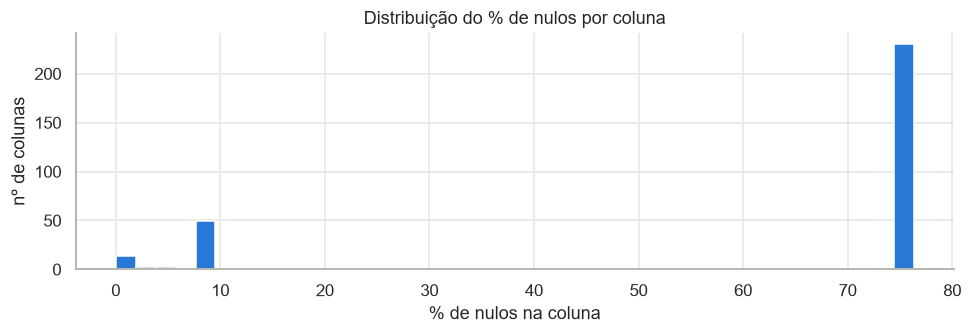

faixa,0%,≤5%,5–30%,30–70%,70–95%,>95%
grupo,,,,,,
alvo,1,0,0,0,0,0
cartão,1,1,7,0,19,0
cliente,0,2,12,0,37,0
conta,0,0,4,0,29,0
dispositivo/terminal,1,2,2,0,31,0
estabelecimento,0,2,7,0,14,0
evento/modelo,1,3,17,0,100,0
transação,2,1,1,0,0,0


In [11]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(perfil.pct_nulo * 100, bins=40, color=COR_LEGIT, edgecolor="white", linewidth=1)
ax.set(title="Distribuição do % de nulos por coluna", xlabel="% de nulos na coluna", ylabel="nº de colunas")
plt.tight_layout(); plt.show()

perfil.assign(faixa=pd.cut(perfil.pct_nulo, [-0.01, 0, 0.05, 0.3, 0.7, 0.95, 1],
                           labels=["0%", "≤5%", "5–30%", "30–70%", "70–95%", ">95%"])) \
      .groupby(["grupo", "faixa"], observed=False).size().unstack(fill_value=0)

**Quais colunas estão em cada faixa de nulos:**

In [12]:
faixa_nulo = pd.cut(perfil.pct_nulo, [-0.01, 0, 0.05, 0.3, 0.7, 0.95, 1],
                    labels=["0%", "≤5%", "5–30%", "30–70%", "70–95%", ">95%"])
for f, cols in perfil.groupby(faixa_nulo, observed=True).groups.items():
    print(f"\n■ {f} de nulos ({len(cols)} colunas)")
    print(", ".join(sorted(cols)))


■ 0% de nulos (6 colunas)
card_presence_flag, device_ip_country_code, event_external_id, feedback_label, modalidade_transacao, tipo_transacao

■ ≤5% de nulos (11 colunas)
acceptor_city, acceptor_id, amount, card_id, customer_city, customer_id, device_id, event_occurred_at, fraud_score, mcc, pos_environment

■ 5–30% de nulos (50 colunas)
acceptor_country_code, acceptor_dba_name, acceptor_email, acceptor_name, acceptor_phone, acceptor_region, acceptor_risk, account_available_credit, account_balance, account_currency, account_id, allow_contactless, allow_crossborder, allow_ecommerce, amount_fees, card_brand, card_country_code, card_credit_limit, card_last4, card_pan, card_type, cardholder_name, cardid_count_1m, cp_card_prev_term_dist_1h, cp_card_term_vel_1h, currency_code, customer_citizen_id_number, customer_country_code, customer_currency, customer_email, customer_name, customer_phone, customer_presumed_income, customer_region, customer_reported_income, customer_risk_rating, customer_t

**A ausência é informativa?** Para cada coluna comparamos o % de nulos nas fraudes e nas legítimas. Uma diferença grande indica que **"estar nulo" é um sinal** e deve virar uma flag `<coluna>_ausente` em vez de ser só imputado.

In [13]:
nulo_por_classe = pd.DataFrame({
    "nulo_fraude": df[y].isna().mean(),
    "nulo_legit": df[~y].isna().mean(),
})
nulo_por_classe["diferenca_pp"] = (nulo_por_classe.nulo_fraude - nulo_por_classe.nulo_legit) * 100
nulo_por_classe = nulo_por_classe[(nulo_por_classe.nulo_fraude + nulo_por_classe.nulo_legit) > 0]
# teste z de duas proporções: a diferença é maior do que o acaso explicaria?
n1, n0 = y.sum(), (~y).sum()
p_pool = (nulo_por_classe.nulo_fraude * n1 + nulo_por_classe.nulo_legit * n0) / (n1 + n0)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n0))
nulo_por_classe["p_valor"] = 2 * norm.sf(np.abs(nulo_por_classe.diferenca_pp / 100) / se)
ALFA = 0.05 / len(nulo_por_classe)   # correção de Bonferroni: muitas colunas testadas ao mesmo tempo
nulo_por_classe["significativo"] = nulo_por_classe.p_valor < ALFA
print(f"Colunas com diferença de nulos significativa (Bonferroni, α={ALFA:.1e}): {nulo_por_classe.significativo.sum()}")
nulo_por_classe.reindex(nulo_por_classe.diferenca_pp.abs().sort_values(ascending=False).index).head(20).round(4)

Colunas com diferença de nulos significativa (Bonferroni, α=1.7e-04): 0


,nulo_fraude,nulo_legit,diferenca_pp,p_valor,significativo
destination_id,0.8562,0.7614,9.4738,0.0073,False
account_number_of_cards,0.8493,0.7583,9.1036,0.0102,False
fdz_timestamp,0.8493,0.7592,9.0147,0.0109,False
terminal_poc_flag,0.6712,0.7591,-8.7910,0.0130,False
account_iban,0.8425,0.7585,8.3974,0.0178,False
pos_cardholder_ver_method,0.6849,0.7615,-7.6601,0.0300,False
terminal_ip_zip,0.6849,0.7604,-7.5500,0.0327,False
account_status,0.6849,0.7592,-7.4318,0.0358,False
card_first_activation_date,0.8288,0.7586,7.0194,0.0476,False
login_session_id,0.6918,0.7613,-6.9558,0.0488,False


**Padrão esperado no case:**
- Um bloco de ~8% de nulos em **variáveis relevantes**: precisa de imputação e flag de ausência.
- Um bloco de ~76% de nulos em **campos secundários**: candidato a remoção, a menos que tenha sinal (seções 8 e 9).

**Cuidado com o acaso:** com poucas fraudes, o % de nulos nas fraudes oscila vários pontos só por sorte (com 146 fraudes, o desvio-padrão é de ~3,5 p.p.). Por isso usamos um teste com correção para múltiplas comparações. Uma diferença só é sinal se for `significativo`.

## 5. Qualidade: valores inválidos e inconsistências

In [14]:
num = lambda c: pd.to_numeric(df[c], errors="coerce")
checks = {
    "amount <= 0": (num("amount") <= 0).sum(),
    "amount nulo": df["amount"].isna().sum(),
}
for c in [c for c in df.columns if c.endswith("_latitude")]:
    checks[f"{c} fora de [-90, 90]"] = (num(c).abs() > 90).sum()
for c in [c for c in df.columns if c.endswith("_longitude")]:
    checks[f"{c} fora de [-180, 180]"] = (num(c).abs() > 180).sum()

t_evento = pd.to_datetime(df["event_occurred_at"], errors="coerce")
t_receb = pd.to_datetime(df["event_received_at"], errors="coerce")
checks["event_occurred_at inválido/nulo"] = t_evento.isna().sum()
checks["recebido ANTES de ocorrido"] = (t_receb < t_evento).sum()
pd.Series(checks, name="ocorrências").to_frame()

,ocorrências
amount <= 0,0
amount nulo,599
"acceptor_latitude fora de [-90, 90]",0
"device_ip_latitude fora de [-90, 90]",0
"terminal_ip_latitude fora de [-90, 90]",0
"terminal_latitude fora de [-90, 90]",0
"acceptor_longitude fora de [-180, 180]",0
"device_ip_longitude fora de [-180, 180]",0
"terminal_ip_longitude fora de [-180, 180]",0
"terminal_longitude fora de [-180, 180]",0


In [15]:
# Pares de colunas que parecem redundantes: estão sempre iguais?
pares = [("cvv2_presence_indicator", "cvv2_present_indicator"),
         ("secure_3d_indicator", "f3ds_secure_indicator"),
         ("secure_3d_protocol_version", "f3ds_secure_protocol_version"),
         ("card_presence_flag", "modalidade_transacao"),
         ("pos_environment", "modalidade_transacao"),
         ("event_occurred_at", "local_datetime")]
for a, b in pares:
    if a in df and b in df:
        print(f"\n{a} × {b}")
        if max(perfil.n_unicos[a], perfil.n_unicos[b]) > 50:
            ambos = df[a].notna() & df[b].notna()
            iguais = (df.loc[ambos, a].astype(str) == df.loc[ambos, b].astype(str)).mean()
            print(f"  iguais em {iguais:.1%} das linhas com ambos preenchidos")
        else:
            print(pd.crosstab(df[a].astype(str).str[:25], df[b].astype(str).str[:25]).iloc[:6, :6])


cvv2_presence_indicator × cvv2_present_indicator
cvv2_present_indicator   SYN_cvv2_present_ind_00  SYN_cvv2_present_ind_01  SYN_cvv2_present_ind_02  SYN_cvv2_present_ind_03  SYN_cvv2_present_ind_04  SYN_cvv2_present_ind_05
cvv2_presence_indicator                                                                                                                                                      
SYN_cvv2_presence_in_00                      221                        0                        0                        0                        0                        0
SYN_cvv2_presence_in_01                        0                      267                        0                        0                        0                        0
SYN_cvv2_presence_in_02                        0                        0                      263                        0                        0                        0
SYN_cvv2_presence_in_03                        0                        0       

f3ds_secure_indicator    SYN_f3ds_secure_indi_00  SYN_f3ds_secure_indi_01  SYN_f3ds_secure_indi_02  SYN_f3ds_secure_indi_03  SYN_f3ds_secure_indi_04  SYN_f3ds_secure_indi_05
secure_3d_indicator                                                                                                                                                          
SYN_secure_3d_indica_00                      242                        0                        0                        0                        0                        0
SYN_secure_3d_indica_01                        0                      231                        0                        0                        0                        0
SYN_secure_3d_indica_02                        0                        0                      245                        0                        0                        0
SYN_secure_3d_indica_03                        0                        0                        0                      256       

modalidade_transacao  cartao_nao_presente  cartao_presente
pos_environment                                           
ECOMMERCE                           57367                0
POS                                     0           101363

event_occurred_at × local_datetime


  iguais em 100.0% das linhas com ambos preenchidos


**Decisões:** quando um par é redundante, mantemos só uma coluna. Valores inválidos viram nulo na limpeza (e são tratados como nulo).

## 6. Variável alvo

In [16]:
def taxa(col, d=df, min_n=0):
    t = d.groupby(d[col].astype(str), dropna=False)[ALVO].agg(transacoes="size", fraudes="sum", taxa_fraude="mean")
    t["lift"] = t.taxa_fraude / d[ALVO].mean()
    t["pct_das_fraudes"] = t.fraudes / d[ALVO].sum()
    return t[t.transacoes >= min_n].sort_values("taxa_fraude", ascending=False)

display(pd.crosstab([df.tipo_transacao, df.modalidade_transacao], y, margins=True))
taxa("tipo_transacao").style.format({"taxa_fraude": "{:.3%}", "lift": "{:.1f}x", "pct_das_fraudes": "{:.0%}"})

feedback_label                        False  True     All
tipo_transacao modalidade_transacao                      
credito        cartao_nao_presente    47058   121   47179
               cartao_presente        16531     3   16534
debito         cartao_nao_presente    10612    14   10626
               cartao_presente        85653     8   85661
All                                  159854   146  160000

,transacoes,fraudes,taxa_fraude,lift,pct_das_fraudes
tipo_transacao,,,,,
credito,63713,124,0.195%,2.1x,85%
debito,96287,22,0.023%,0.3x,15%


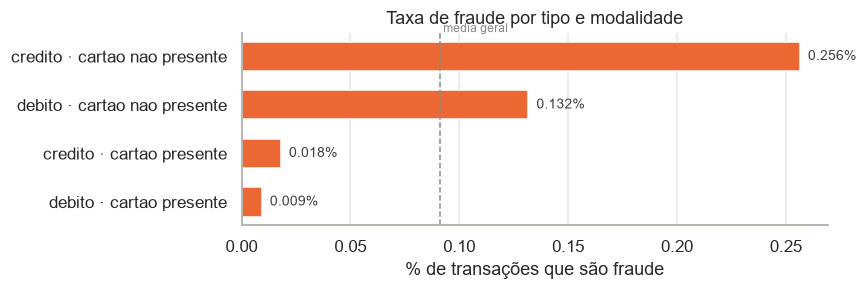

In [17]:
seg = (df.groupby(["tipo_transacao", "modalidade_transacao"])[ALVO].mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh([f"{a} · {b.replace('_', ' ')}" for a, b in seg.index], seg.values, color=COR_FRAUDE, height=0.6)
for i, v in enumerate(seg.values):
    ax.text(v, i, f"  {v:.3f}%", va="center", fontsize=9, color="#3d3d3a")
ax.axvline(y.mean() * 100, color=COR_NEUTRA, ls="--", lw=1)
ax.text(y.mean() * 100, len(seg) - 0.5, " média geral", color=COR_NEUTRA, fontsize=8)
ax.set(title="Taxa de fraude por tipo e modalidade", xlabel="% de transações que são fraude"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Leitura:** o desenho do case diz que a fraude se concentra em **crédito com cartão não presente**. Esse é o primeiro filtro de risco, e também uma escolha de escopo para o modelo: treinar em tudo ou focar no CNP?

**Implicação para a modelagem:** com ~0,1% de positivos, a **acurácia não serve** (um modelo que diz "nunca é fraude" acerta 99,9%). Usaremos PR-AUC, recall e precisão num threshold de negócio.

## 7. Análise temporal

Período: 2025-01-01 00:06:12 → 2025-12-31 23:58:33


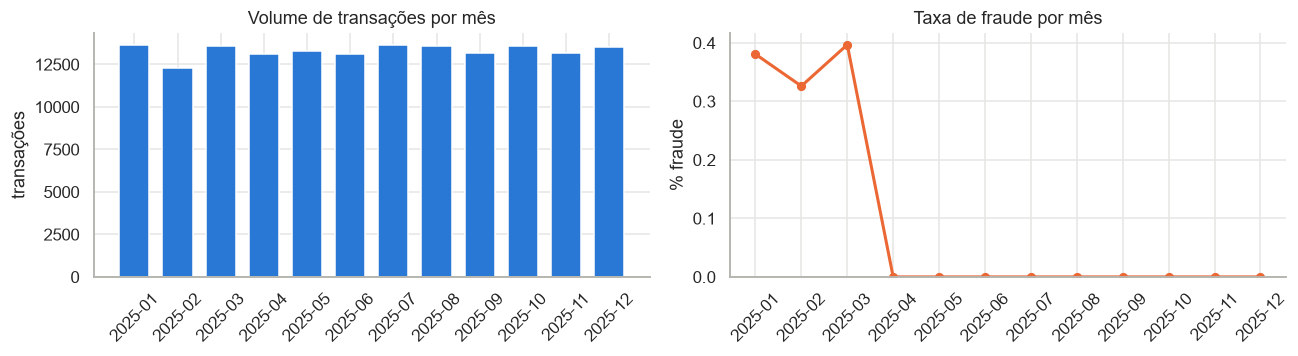

In [18]:
df["ts"] = t_evento
df["hora"] = df.ts.dt.hour
df["dia_semana"] = df.ts.dt.dayofweek
df["mes"] = df.ts.dt.to_period("M")
print("Período:", df.ts.min(), "→", df.ts.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
mensal = df.groupby("mes")[ALVO].agg(["size", "mean"])
axes[0].bar(mensal.index.astype(str), mensal["size"], color=COR_LEGIT, width=0.7)
axes[0].set(title="Volume de transações por mês", ylabel="transações"); axes[0].tick_params(axis="x", rotation=45)
axes[1].plot(mensal.index.astype(str), mensal["mean"] * 100, color=COR_FRAUDE, lw=2, marker="o", ms=5)
axes[1].set(title="Taxa de fraude por mês", ylabel="% fraude"); axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(bottom=0)
plt.tight_layout(); plt.show()

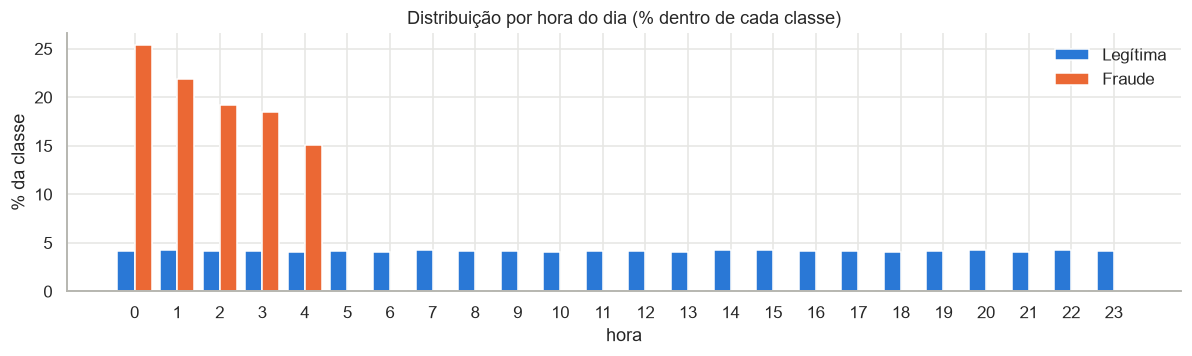

In [19]:
dist_hora = pd.crosstab(df.hora, y, normalize="columns") * 100
fig, ax = plt.subplots(figsize=(11, 3.4))
w = 0.4
ax.bar(dist_hora.index - w/2, dist_hora[False], width=w, color=COR_LEGIT, label="Legítima")
ax.bar(dist_hora.index + w/2, dist_hora[True], width=w, color=COR_FRAUDE, label="Fraude")
ax.set(title="Distribuição por hora do dia (% dentro de cada classe)", xlabel="hora", ylabel="% da classe", xticks=range(24))
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Horários concentrados:** se as fraudes se concentram numa janela (por exemplo, a madrugada) e as legítimas se distribuem igualmente, a hora é um sinal forte.

Mas cuidado: num dado sintético, uma separação *perfeita* por hora é um artefato do gerador e pode não generalizar. Vale usar a hora como feature, sem depender só dela.

**Validação temporal:** vamos dividir **por data** (ex.: treino = jan–set, validação = out, teste = nov–dez), nunca de forma aleatória. Assim simulamos o uso real: o modelo prevê o futuro com dados do passado. A tabela abaixo mostra quantas fraudes cada corte teria.

> ⚠️ **Verificar:** no arquivo parcial de 160 mil linhas, **todas as fraudes caem em jan–mar** e não há nenhuma de abril a dezembro. Se isso se repetir na base completa, o split temporal "puro" deixa validação e teste sem fraudes, e precisaremos de outra estratégia (ex.: split temporal dentro do período com fraude, ou estratificado por mês).

In [20]:
df.groupby("mes")[ALVO].agg(transacoes="size", fraudes="sum").T

mes,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
transacoes,13658,12265,13608,13125,13300,13085,13639,13568,13155,13581,13181,13524
fraudes,52,40,54,0,0,0,0,0,0,0,0,0


## 8. Variáveis categóricas × fraude

Para cada categórica de baixa cardinalidade calculamos a **taxa de fraude e o lift** (taxa da categoria ÷ taxa geral) por categoria. Só mostramos categorias com volume mínimo, para não confundir acaso com sinal: com 0,1% de fraude, uma categoria com 300 transações deveria ter só ~0,3 fraude.

Também resumimos cada coluna com o **lift máximo** e um **teste qui-quadrado** (categoria × fraude, com correção de Bonferroni). O lift mostra o *tamanho* do efeito; o teste diz se ele é *maior que o acaso*. Com poucas fraudes por categoria, um lift alto sem significância é ruído.

In [21]:
MIN_N = 500
cat_cols = [c for c in df.columns
            if c not in [ALVO, "ts", "hora", "dia_semana", "mes"]
            and 2 <= perfil.n_unicos.get(c, 0) <= 60]

def p_chi2(c):
    m = df[c].notna()
    tab = pd.crosstab(df.loc[m, c].astype(str), y[m])
    return chi2_contingency(tab)[1] if tab.shape[0] > 1 and tab.shape[1] == 2 else np.nan

resumo_cat = []
for c in cat_cols:
    t = taxa(c, min_n=MIN_N)
    if len(t) < 2:
        continue
    resumo_cat.append({"coluna": c, "grupo": grupo.get(c), "pct_nulo": perfil.pct_nulo[c],
                       "n_categorias": perfil.n_unicos[c],
                       "lift_max": t.lift.max(), "lift_min": t.lift.min(), "p_chi2": p_chi2(c),
                       "categoria_mais_arriscada": t.index[0]})
resumo_cat = pd.DataFrame(resumo_cat)
ALFA_CAT = 0.05 / len(resumo_cat)
resumo_cat["significativo"] = resumo_cat.p_chi2 < ALFA_CAT
print(f"{resumo_cat.significativo.sum()} de {len(resumo_cat)} categóricas com associação significativa (α={ALFA_CAT:.1e})")
resumo_cat.sort_values(["significativo", "lift_max"], ascending=False).head(30).round(4)

9 de 164 categóricas com associação significativa (α=3.0e-04)


,coluna,grupo,pct_nulo,n_categorias,lift_max,lift_min,p_chi2,categoria_mais_arriscada,significativo
123,pos_environment,dispositivo/terminal,0.0079,2,2.5598,0.1189,0.0000,ECOMMERCE,True
163,modalidade_transacao,transação,0.0000,2,2.5594,0.1180,0.0000,cartao_nao_presente,True
41,card_presence_flag,cartão,0.0000,2,2.2583,0.1166,0.0000,N,True
162,tipo_transacao,transação,0.0000,2,2.1329,0.2504,0.0000,credito,True
45,card_type,cartão,0.0811,2,2.0969,0.2353,0.0000,credito,True
75,decision,evento/modelo,0.0801,2,1.6239,0.3725,0.0000,NaN,True
147,transaction_status,evento/modelo,0.0807,2,1.1040,0.6335,0.0000,NaN,True
53,cardid_count_1m,cartão,0.0807,29,1.1037,0.0000,0.0000,NaN,True
77,device_ip_country_code,dispositivo/terminal,0.0000,3,0.7512,0.7389,0.0000,No,True
90,fdz_triggered_actions,evento/modelo,0.7595,37,6.2742,0.0000,0.0268,SYN_fdz_triggered_ac_21,False


In [22]:
for c in ["modalidade_transacao", "pos_environment", "card_presence_flag", "pos_card_read_method",
          "card_brand", "card_category", "mcc", "customer_segment", "device_ip_country_code", "acceptor_risky_flag"]:
    if c in df:
        print(f"\n=== {c} (nulos: {perfil.pct_nulo[c]:.1%})")
        display(taxa(c, min_n=30).head(8).style.format({"taxa_fraude": "{:.3%}", "lift": "{:.1f}x", "pct_das_fraudes": "{:.0%}"}))


=== modalidade_transacao (nulos: 0.0%)


,transacoes,fraudes,taxa_fraude,lift,pct_das_fraudes
modalidade_transacao,,,,,
cartao_nao_presente,57805,135,0.234%,2.6x,92%
cartao_presente,102195,11,0.011%,0.1x,8%



=== pos_environment (nulos: 0.8%)


,transacoes,fraudes,taxa_fraude,lift,pct_das_fraudes
pos_environment,,,,,
ECOMMERCE,57367,134,0.234%,2.6x,92%
nan,1270,1,0.079%,0.9x,1%
POS,101363,11,0.011%,0.1x,8%



=== card_presence_flag (nulos: 0.0%)


...

,transacoes,fraudes,taxa_fraude,lift,pct_das_fraudes
customer_segment,,,,,
SYN_customer_segment_17,1024,5,0.488%,5.4x,3%
SYN_customer_segment_23,997,3,0.301%,3.3x,2%
SYN_customer_segment_34,1012,3,0.296%,3.2x,2%
SYN_customer_segment_33,1047,3,0.287%,3.1x,2%
SYN_customer_segment_02,1026,2,0.195%,2.1x,1%
SYN_customer_segment_16,1041,2,0.192%,2.1x,1%
SYN_customer_segment_08,1043,2,0.192%,2.1x,1%
SYN_customer_segment_11,1047,2,0.191%,2.1x,1%



=== device_ip_country_code (nulos: 0.0%)


,transacoes,fraudes,taxa_fraude,lift,pct_das_fraudes
device_ip_country_code,,,,,
ZZ,38,38,100.000%,1095.9x,26%
No,13130,9,0.069%,0.8x,6%
BR,146832,99,0.067%,0.7x,68%



=== acceptor_risky_flag (nulos: 76.0%)


,transacoes,fraudes,taxa_fraude,lift,pct_das_fraudes
acceptor_risky_flag,,,,,
nan,121582,112,0.092%,1.0x,77%


**Atenção aos campos `SYN_...` com ~76% de nulos.** As categorias têm ~1.000 transações cada, o que dá só uma ou duas fraudes por categoria. Lifts de 2–6x nesse volume são compatíveis com acaso, e o teste qui-quadrado confirma: eles não são significativos. A seção 13 os trata como **ruído**, a menos que o sinal se confirme na base completa.

## 9. Variáveis numéricas × fraude

Para cada numérica calculamos a **AUC univariada**: o quanto aquela variável sozinha ordena fraude acima de legítima. 0,5 = nenhum sinal; 1,0 = separação perfeita. Usamos `max(AUC, 1-AUC)`, já que o sinal pode estar em qualquer direção.

> Uma AUC ≈ 1,0 numa única coluna é **suspeita de vazamento** ou de feature "pronta" (ver seção 10).

In [23]:
excluir = {ALVO, "hora", "dia_semana"}
num_cols = [c for c in df.columns if c not in excluir and
            (pd.api.types.is_numeric_dtype(df[c]) or perfil.numerico_em_texto.get(c, False))
            and not pd.api.types.is_bool_dtype(df[c])]
num_cols += ["hora"]

linhas = []
for c in num_cols:
    s = pd.to_numeric(df[c], errors="coerce"); m = s.notna()
    if m.sum() < 1000 or y[m].sum() < 10 or s[m].nunique() < 2:
        continue
    auc = roc_auc_score(y[m], s[m])
    linhas.append({"coluna": c, "grupo": grupo.get(c, "derivada"), "auc": max(auc, 1 - auc),
                   "direcao": "maior = mais fraude" if auc >= 0.5 else "menor = mais fraude",
                   "pct_nulo": 1 - m.mean(), "mediana_fraude": s[y].median(), "mediana_legit": s[~y].median()})
auc_num = pd.DataFrame(linhas).sort_values("auc", ascending=False).reset_index(drop=True)
auc_num.head(25).round(3)

,coluna,grupo,auc,direcao,pct_nulo,mediana_fraude,mediana_legit
0,cp_card_term_vel_1h,evento/modelo,1.000,maior = mais fraude,0.080,47.000,2.000
1,digitalwallettoken_count_3m,evento/modelo,1.000,maior = mais fraude,0.080,80.000,7.000
2,cardid_count_1m,cartão,1.000,maior = mais fraude,0.081,17.000,1.000
3,fraud_score,evento/modelo,1.000,maior = mais fraude,0.012,842.500,190.000
4,mc_fraud_score,evento/modelo,1.000,maior = mais fraude,0.079,839.500,189.000
5,visa_fraud_score,evento/modelo,1.000,maior = mais fraude,0.079,856.000,190.000
6,cp_card_prev_term_dist_1h,evento/modelo,0.956,maior = mais fraude,0.080,277.820,12.480
7,acceptor_risk,estabelecimento,0.917,maior = mais fraude,0.079,41.000,18.000
8,hora,derivada,0.905,menor = mais fraude,0.002,2.000,11.000
9,amount,transação,0.888,maior = mais fraude,0.004,190.345,34.770


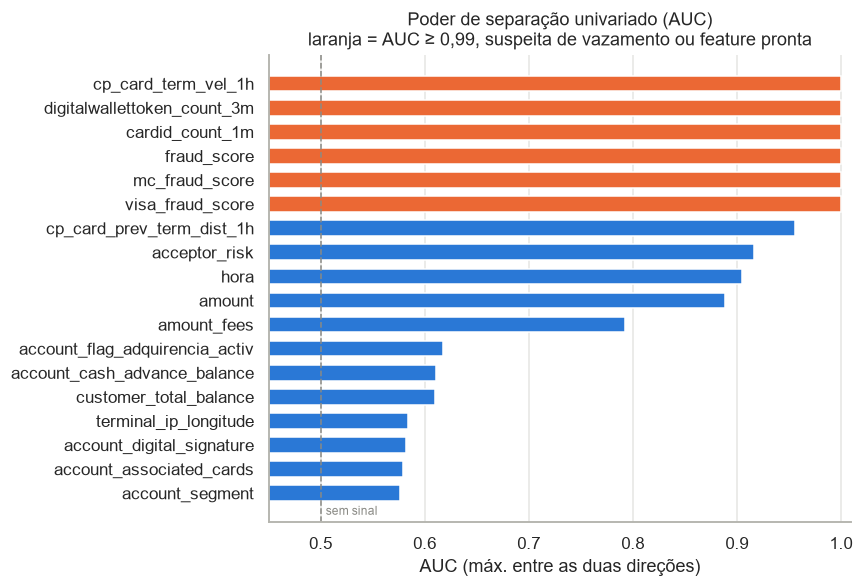

In [24]:
top = auc_num.head(18).iloc[::-1]
cores = [COR_FRAUDE if a >= 0.99 else COR_LEGIT for a in top.auc]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.coluna, top.auc, color=cores, height=0.65)
ax.axvline(0.5, color=COR_NEUTRA, lw=1, ls="--"); ax.text(0.505, -0.9, "sem sinal", color=COR_NEUTRA, fontsize=8)
ax.set(xlim=(0.45, 1.01), title="Poder de separação univariado (AUC)\nlaranja = AUC ≥ 0,99, suspeita de vazamento ou feature pronta",
       xlabel="AUC (máx. entre as duas direções)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

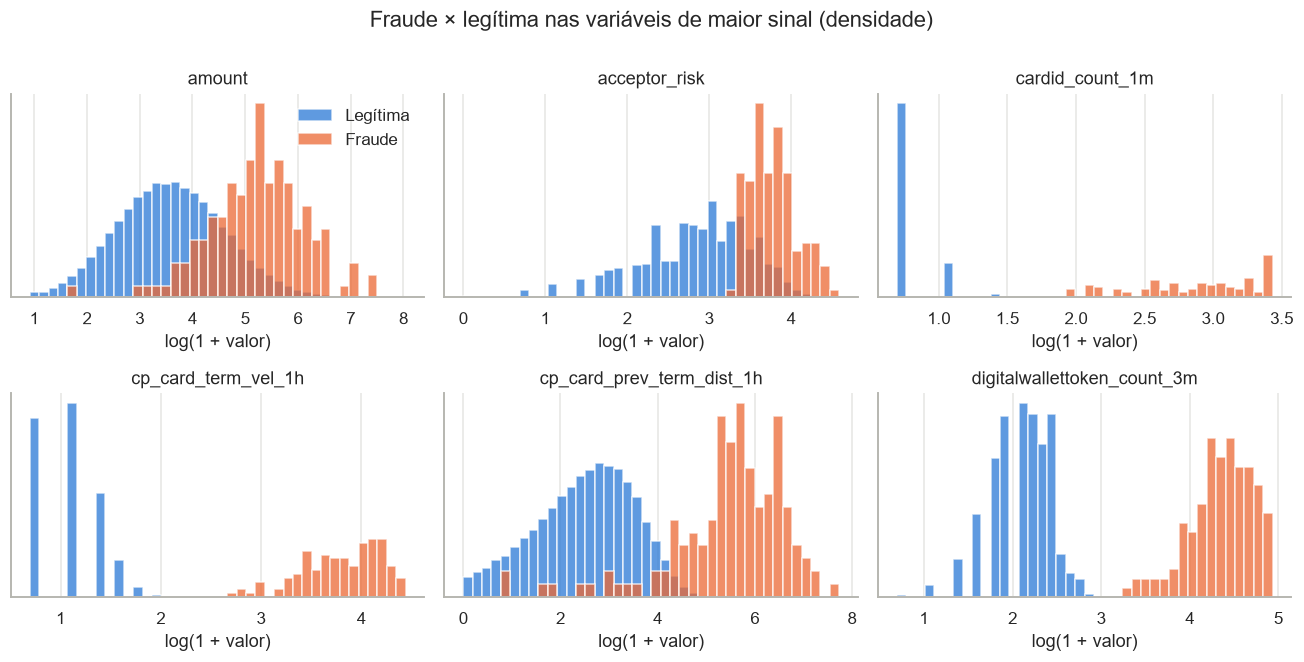

In [25]:
# Distribuições das variáveis mais fortes (escala log1p para valores monetários e contagens)
vars_plot = [c for c in ["amount", "acceptor_risk", "cardid_count_1m", "cp_card_term_vel_1h",
                         "cp_card_prev_term_dist_1h", "digitalwallettoken_count_3m"] if c in df]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.ravel(), vars_plot):
    s = np.log1p(pd.to_numeric(df[c], errors="coerce").clip(lower=0))
    bins = np.histogram_bin_edges(s.dropna(), bins=40)
    ax.hist(s[~y].dropna(), bins=bins, density=True, color=COR_LEGIT, alpha=0.75, label="Legítima")
    ax.hist(s[y].dropna(), bins=bins, density=True, color=COR_FRAUDE, alpha=0.75, label="Fraude")
    ax.set(title=c, xlabel="log(1 + valor)", yticks=[])
axes[0, 0].legend(frameon=False)
fig.suptitle("Fraude × legítima nas variáveis de maior sinal (densidade)", y=1.0)
plt.tight_layout(); plt.show()

**Os sinais descritos no case e onde aparecem:**

| Sinal do case | Colunas que o capturam |
|---|---|
| Valores anômalos | `amount`, `amount_fees` |
| Alta velocidade / rajadas | `cardid_count_1m`, `cp_card_term_vel_1h`, `digitalwallettoken_count_3m` |
| Divergência geográfica | `cp_card_prev_term_dist_1h` (+ distâncias da seção 12) |
| Horários concentrados | `hora` |
| Risco do estabelecimento | `acceptor_risk` |

## 10. Vazamento (leakage)

Uma coluna "vaza" quando contém informação que **só existe depois** de saber se foi fraude: a decisão tomada, o status final, a disputa aberta, o feedback do analista. Um modelo treinado com ela parece perfeito no papel e não funciona em produção.

Usamos três critérios:
1. **Por definição** (nome/semântica): decisão, status, disputa, feedback, alerta, contato pós-transação (OOB).
2. **Por evidência**: categorias com 100% de fraude e volume relevante.
3. **Por evidência**: AUC univariada ≥ 0,99.

In [26]:
# Critério 2: categorias que são 100% fraude (com pelo menos 20 transações)
evid = []
for c in [c for c in df.columns if 2 <= perfil.n_unicos.get(c, 0) <= 5000 and c != ALVO]:
    t = taxa(c, min_n=20)
    hit = t[t.taxa_fraude == 1]
    for cat, r in hit.iterrows():
        evid.append({"coluna": c, "categoria": cat, "transacoes": int(r.transacoes), "pct_das_fraudes": r.pct_das_fraudes})
pd.DataFrame(evid)

,coluna,categoria,transacoes,pct_das_fraudes
0,decision,deny,77,0.527397
1,device_ip_country_code,ZZ,38,0.260274
2,transaction_status,declined,48,0.328767


In [27]:
LEAK_SEMANTICO = [c for c in df.columns if any(c.startswith(p) for p in
                  ["dispute_", "fdz_", "oob_", "alert_", "lists_state", "decision", "transaction_status",
                   "action_code", "approval_code", "reason_code", "event_treatment_date", "trx_to_rec_conv_date"])] + ["fraud"]
LEAK_EVIDENCIA = sorted({e["coluna"] for e in evid})
SCORES_EXTERNOS = ["fraud_score", "visa_fraud_score", "mc_fraud_score"]

print("Vazamento por definição:", LEAK_SEMANTICO)
print("Vazamento por evidência (categoria 100% fraude):", LEAK_EVIDENCIA)
print("AUC ≥ 0,99:", auc_num.query("auc >= 0.99").coluna.tolist())

Vazamento por definição: ['action_code', 'alert_id', 'approval_code', 'decision', 'dispute_end_date', 'dispute_feedback_notes', 'dispute_notes', 'dispute_reason', 'dispute_refunded', 'dispute_start_date', 'dispute_submitted_by', 'fdz_exposed_schema_diffb', 'fdz_feedbacks', 'fdz_partition_index', 'fdz_timestamp', 'fdz_triggered_actions', 'fdz_uuid', 'lists_state', 'oob_comm_type', 'oob_end_date', 'oob_feedback_notes', 'oob_notes', 'oob_response_type', 'oob_start_date', 'reason_code', 'transaction_status', 'trx_to_rec_conv_date', 'event_treatment_date', 'fraud']
Vazamento por evidência (categoria 100% fraude): ['decision', 'device_ip_country_code', 'transaction_status']
AUC ≥ 0,99: ['cp_card_term_vel_1h', 'digitalwallettoken_count_3m', 'cardid_count_1m', 'fraud_score', 'mc_fraud_score', 'visa_fraud_score']


In [28]:
# Os scores externos: quão bons são sozinhos? Servem de BASELINE para comparar o nosso modelo.
for c in SCORES_EXTERNOS:
    s = pd.to_numeric(df[c], errors="coerce")
    print(f"{c:18s} | máx. legítima: {s[~y].max():6.0f} | mín. fraude: {s[y].min():6.0f} | nulos: {s.isna().mean():.1%}")

s = df.fraud_score
for corte in [500, 600, 650, 700]:
    m = s > corte
    print(f"fraud_score > {corte}: sinaliza {m.sum():5d} | precisão {y[m].mean():.1%} | recall {m[y].mean():.1%}")

fraud_score        | máx. legítima:    664 | mín. fraude:    600 | nulos: 1.2%
visa_fraud_score   | máx. legítima:    651 | mín. fraude:    514 | nulos: 7.9%
mc_fraud_score     | máx. legítima:    667 | mín. fraude:    537 | nulos: 7.9%
fraud_score > 500: sinaliza   494 | precisão 29.1% | recall 98.6%
fraud_score > 600: sinaliza   157 | precisão 91.1% | recall 97.9%
fraud_score > 650: sinaliza   142 | precisão 97.9% | recall 95.2%
fraud_score > 700: sinaliza   136 | precisão 100.0% | recall 93.2%


**Decisões:**
- **Vazamento** (por definição ou evidência): sai da base de modelagem.
- **Scores externos** (`fraud_score`, Visa, Mastercard): são o resultado de outro modelo de fraude e separam as classes quase perfeitamente. Não entram como feature, para não "copiarmos" o modelo existente. Ficam como **baseline**: nosso modelo deve ser comparado a eles.
- **Features de velocidade com AUC ≈ 1** (`cardid_count_1m`, `cp_card_term_vel_1h`, `digitalwallettoken_count_3m`): são sinais *legítimos* (calculados antes da transação), mas fortes demais por serem sintéticas. Ficam como **nível B** e o modelo é avaliado com e sem elas.

## 11. Entidades e velocidade

In [29]:
ents = ["card_id", "customer_id", "account_id", "device_id", "acceptor_id", "terminal_id"]
resumo_ent = []
for e in [e for e in ents if e in df]:
    g = df.groupby(e)[ALVO].agg(["size", "sum"])
    resumo_ent.append({"entidade": e, "distintos": len(g), "trx_por_entidade_mediana": g["size"].median(),
                       "trx_por_entidade_max": g["size"].max(), "entidades_com_fraude": (g["sum"] > 0).sum(),
                       "max_fraudes_numa_entidade": g["sum"].max()})
pd.DataFrame(resumo_ent)

,entidade,distintos,trx_por_entidade_mediana,trx_por_entidade_max,entidades_com_fraude,max_fraudes_numa_entidade
0,card_id,56772,2.0,448,145,1
1,customer_id,33037,2.0,1326,143,3
2,account_id,31938,2.0,1224,125,2
3,device_id,80816,1.0,189,144,2
4,acceptor_id,6610,3.0,580,132,3
5,terminal_id,17996,8.0,21,141,1


**Por que importa:**
1. **Agregações:** se cartões, clientes e devices se repetem, dá para calcular o histórico de cada um (média de gasto, nº de transações recentes, device novo?).
2. **Divisão treino/teste:** se uma entidade tem várias fraudes, ela não pode aparecer no treino e no teste ao mesmo tempo. O split temporal ajuda, mas vale checar.

In [30]:
# As "rajadas" aparecem nos dados brutos? Tempo desde a transação anterior do mesmo cartão.
d = df[["card_id", "ts", "amount", ALVO]].dropna(subset=["card_id", "ts"]).sort_values(["card_id", "ts"])
d["min_desde_anterior"] = d.groupby("card_id")["ts"].diff().dt.total_seconds() / 60
d["valor_vs_media_cartao"] = d["amount"] / d.groupby("card_id")["amount"].transform(
    lambda s: s.shift().expanding().mean())

yy = d[ALVO]
print("Minutos desde a transação anterior do cartão (mediana): fraude =",
      round(d.loc[yy, "min_desde_anterior"].median()), "| legítima =", round(d.loc[~yy, "min_desde_anterior"].median()))
print("% com transação anterior < 60 min: fraude =", f"{(d.loc[yy,'min_desde_anterior'] < 60).mean():.1%}",
      "| legítima =", f"{(d.loc[~yy,'min_desde_anterior'] < 60).mean():.1%}")
print("Valor ÷ média histórica do cartão (mediana): fraude =", round(d.loc[yy, "valor_vs_media_cartao"].median(), 2),
      "| legítima =", round(d.loc[~yy, "valor_vs_media_cartao"].median(), 2))

Minutos desde a transação anterior do cartão (mediana): fraude = 21014 | legítima = 55208
% com transação anterior < 60 min: fraude = 0.0% | legítima = 0.1%
Valor ÷ média histórica do cartão (mediana): fraude = 3.9 | legítima = 0.76


**Leitura:** se as fraudes **não** estão próximas de outras transações do mesmo cartão nos dados brutos, então as "rajadas" do case existem só nas **colunas pré-calculadas** de velocidade, e não dá para reconstruí-las a partir das linhas. Isso reforça usar essas colunas como features prontas (nível B).

Já a razão *valor ÷ média histórica do cartão* pode ser calculada sem vazamento (usa só transações anteriores) e é candidata a feature nova.

## 12. Geografia

In [31]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = [np.radians(pd.to_numeric(x, errors="coerce")) for x in (lat1, lon1, lat2, lon2)]
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

pontos = {"estab": "acceptor", "terminal": "terminal", "ip_device": "device_ip", "ip_terminal": "terminal_ip"}
geo = {}
nomes = list(pontos)
for i, a in enumerate(nomes):
    for b in nomes[i + 1:]:
        pa, pb = pontos[a], pontos[b]
        geo[f"dist_{a}_{b}_km"] = haversine_km(df[f"{pa}_latitude"], df[f"{pa}_longitude"],
                                               df[f"{pb}_latitude"], df[f"{pb}_longitude"])
geo = pd.DataFrame(geo)

linhas = []
for c in geo:
    m = geo[c].notna()
    auc = roc_auc_score(y[m], geo.loc[m, c]) if y[m].sum() >= 10 else np.nan
    linhas.append({"distancia": c, "linhas_calculaveis": int(m.sum()), "fraudes_calculaveis": int(y[m].sum()),
                   "auc": max(auc, 1 - auc) if pd.notna(auc) else np.nan,
                   "mediana_fraude_km": geo.loc[m & y, c].median(), "mediana_legit_km": geo.loc[m & ~y, c].median()})
pd.DataFrame(linhas).round(3)

,distancia,linhas_calculaveis,fraudes_calculaveis,auc,mediana_fraude_km,mediana_legit_km
0,dist_estab_terminal_km,555,0,NaN,NaN,1638.258
1,dist_estab_ip_device_km,542,0,NaN,NaN,1710.043
2,dist_estab_ip_terminal_km,525,0,NaN,NaN,1612.974
3,dist_terminal_ip_device_km,554,0,NaN,NaN,1594.256
4,dist_terminal_ip_terminal_km,535,0,NaN,NaN,1665.645
5,dist_ip_device_ip_terminal_km,544,1,NaN,1330.31,1606.014


In [32]:
# Por que tão poucas distâncias são calculáveis? Latitude e longitude ficam nulas de forma independente.
coords = [c for c in df.columns if c.endswith(("_latitude", "_longitude"))]
print("% nulo por coordenada:"); print(df[coords].isna().mean().round(3).to_string())
lat, lon = "terminal_latitude", "terminal_longitude"
print(f"\nP(lat nula) × P(lon nula) = {df[lat].isna().mean() * df[lon].isna().mean():.3f} "
      f"| observado P(ambas nulas) = {(df[lat].isna() & df[lon].isna()).mean():.3f}  → independentes")

% nulo por coordenada:
acceptor_latitude        0.761
acceptor_longitude       0.759
device_ip_latitude       0.759
device_ip_longitude      0.761
terminal_ip_latitude     0.760
terminal_ip_longitude    0.761
terminal_latitude        0.760
terminal_longitude       0.760

P(lat nula) × P(lon nula) = 0.578 | observado P(ambas nulas) = 0.579  → independentes


In [33]:
# Divergência de país: IP do device × país do cartão × país do cliente
for a, b in [("device_ip_country_code", "card_country_code"), ("device_ip_country_code", "customer_country_code"),
             ("terminal_ip_country_code", "card_country_code")]:
    if a in df and b in df:
        diverge = (df[a].astype(str) != df[b].astype(str)) & df[a].notna() & df[b].notna()
        print(f"{a} ≠ {b}: {diverge.mean():.2%} das transações | taxa de fraude se diverge: "
              f"{y[diverge].mean():.3%} vs. {y[~diverge].mean():.3%}")

device_ip_country_code ≠ card_country_code: 7.56% das transações | taxa de fraude se diverge: 0.372% vs. 0.068%
device_ip_country_code ≠ customer_country_code: 7.60% das transações | taxa de fraude se diverge: 0.362% vs. 0.069%


terminal_ip_country_code ≠ card_country_code: 22.20% das transações | taxa de fraude se diverge: 0.087% vs. 0.092%


**Leitura e decisões:**
- As coordenadas brutas têm ~76% de nulos, e latitude e longitude somem de forma independente. Uma distância só é calculável quando os 4 valores existem, o que deixa pouquíssimas linhas. Na prática, **a geografia bruta não serve como feature**: as coordenadas vão para `remover_ruido`.
- O sinal de **divergência geográfica** do case está na coluna pronta `cp_card_prev_term_dist_1h` (nível B).
- A divergência de país precisa ser avaliada **sem** o código `ZZ`, que é um vazamento (seção 10).

## 13. Triagem de colunas: proposta para a base de modelagem

Regras aplicadas, em ordem de prioridade:

| Decisão | Critério |
|---|---|
| `remover_vazamento` | definição semântica ou evidência (seção 10) |
| `baseline_externo` | scores de fraude de terceiros: só para comparação |
| `remover_pii` | dados pessoais/contato/documentos (placeholders, sem sinal, e o programa proíbe PII) |
| `id_agregacao` | IDs: não entram direto, mas servem para criar features |
| `remover_constante` | ≤ 1 valor distinto |
| `remover_ruido` | > 70% nulos e sem sinal (AUC < 0,6 e associação categórica não significativa) |
| `nivel_B_pre_calculada` | velocidade/distância já calculadas, AUC ≥ 0,99 |
| `manter` | todo o resto |

In [34]:
PII_TOKENS = ["_name", "email", "phone", "ssn", "passport", "driver_license", "citizen_id", "tax_number",
              "street_addr", "_dob", "username", "iban", "card_pan", "card_last4", "certificate_number",
              "_url", "digital_signature", "contact_info", "cardholder_add_id", "cardholder_id_number",
              "compress_bill_addr", "_zip"]
IP_COLS = ["device_ip", "terminal_ip"]
ID_COLS = ["card_id", "customer_id", "account_id", "device_id", "acceptor_id", "terminal_id", "session_id",
           "login_session_id", "device_fingerprint", "event_external_id", "retrieval_reference_number",
           "lifecycle_id", "lifecycle_token", "xid", "arn"]
NIVEL_B = ["cardid_count_1m", "cp_card_term_vel_1h", "cp_card_prev_term_dist_1h", "digitalwallettoken_count_3m"]

auc_map = auc_num.set_index("coluna").auc
lift_map = resumo_cat.set_index("coluna").lift_max
sig_map = resumo_cat.set_index("coluna").significativo

def decidir(c):
    if c == ALVO: return "alvo", "variável alvo"
    if c in LEAK_SEMANTICO or c in LEAK_EVIDENCIA: return "remover_vazamento", "informação pós-evento / 100% fraude"
    if c in SCORES_EXTERNOS: return "baseline_externo", "score de outro modelo"
    if c in ID_COLS or c.endswith("_id") and perfil.n_unicos[c] > 1000: return "id_agregacao", "identificador"
    if c in IP_COLS or any(tok in c for tok in PII_TOKENS) and not c.endswith(("_latitude", "_longitude", "_country_code")):
        return "remover_pii", "dado pessoal / contato"
    if perfil.n_unicos[c] <= 1: return "remover_constante", "sem variação"
    if c in NIVEL_B: return "nivel_B_pre_calculada", "velocidade/distância pronta"
    sinal = max(auc_map.get(c, 0.5), 0.5)
    lift = lift_map.get(c, 1.0)
    sig = bool(sig_map.get(c, False))
    if perfil.pct_nulo[c] > 0.70 and sinal < 0.6 and not sig:
        return "remover_ruido", f"{perfil.pct_nulo[c]:.0%} nulo, AUC {sinal:.2f}, lift {lift:.1f} (n.s.)"
    if c in auc_map:
        return "manter", f"numérica, AUC {sinal:.2f}, {perfil.pct_nulo[c]:.0%} nulo"
    return "manter", f"categórica, lift {lift:.1f}{' (signif.)' if sig else ' (n.s.)'}, {perfil.pct_nulo[c]:.0%} nulo"

triagem = pd.DataFrame([(c, grupo.get(c), *decidir(c)) for c in perfil.index],
                       columns=["coluna", "grupo", "decisao", "motivo"])
triagem = triagem.merge(perfil[["pct_nulo", "n_unicos", "dtype"]], left_on="coluna", right_index=True)
triagem.to_csv(OUT / "triagem_colunas.csv", index=False)

display(pd.crosstab(triagem.grupo, triagem.decisao, margins=True))

decisao,alvo,baseline_externo,id_agregacao,manter,nivel_B_pre_calculada,remover_constante,remover_pii,remover_ruido,remover_vazamento,All
grupo,,,,,,,,,,
alvo,1,0,0,0,0,0,0,0,0,1
cartão,0,0,1,4,1,1,2,19,0,28
cliente,0,0,2,6,0,3,22,18,0,51
conta,0,0,1,4,0,1,3,24,0,33
dispositivo/terminal,0,0,3,1,0,0,5,26,1,36
estabelecimento,0,0,1,3,0,1,12,6,0,23
evento/modelo,0,3,16,10,3,2,1,57,29,121
transação,0,0,0,4,0,0,0,0,0,4
All,1,3,24,32,4,8,45,150,30,297


In [35]:
triagem.query("decisao == 'manter'").sort_values(["grupo", "coluna"])

,coluna,grupo,decisao,motivo,pct_nulo,n_unicos,dtype
72,card_brand,cartão,manter,"categórica, lift 1.1 (n.s.), 8% nulo",0.078537,3,str
75,card_credit_limit,cartão,manter,"numérica, AUC 0.51, 8% nulo",0.080200,133471,float64
90,card_presence_flag,cartão,manter,"categórica, lift 2.3 (signif.), 0% nulo",0.000000,2,str
95,card_type,cartão,manter,"categórica, lift 2.1 (signif.), 8% nulo",0.081088,2,str
119,customer_city,cliente,manter,"categórica, lift 1.0 (n.s.), 4% nulo",0.039762,480,str
290,customer_presumed_income,cliente,manter,"numérica, AUC 0.51, 8% nulo",0.080738,128615,float64
138,customer_region,cliente,manter,"categórica, lift 1.5 (n.s.), 8% nulo",0.080381,12,str
291,customer_reported_income,cliente,manter,"numérica, AUC 0.50, 8% nulo",0.079888,129217,float64
140,customer_risk_rating,cliente,manter,"categórica, lift 1.1 (n.s.), 8% nulo",0.080456,3,str
145,customer_total_balance,cliente,manter,"numérica, AUC 0.61, 76% nulo",0.760525,10760,float64


> A tabela é uma **proposta automática**: revisem a lista `manter` em grupo antes de gerar a base. Ela foi salva em `outputs/triagem_colunas.csv`.

## 14. Conclusões e próximos passos

**O que a EDA mostra** (confirme os números ao rodar com a base completa):

1. **Desbalanceamento extremo** (~0,1% de fraude): métricas de avaliação = PR-AUC, recall e precisão num threshold; nada de acurácia.
2. **Onde está a fraude:** crédito + cartão não presente (e-commerce) concentra a grande maioria dos casos.
3. **Sinais legítimos fortes:** hora do dia (madrugada), valor da transação, risco do estabelecimento, velocidade do cartão, distância do terminal anterior.
4. **Vazamento:** `decision`, `transaction_status`, `device_ip_country_code = ZZ` e os campos de disputa, feedback e OOB precisam sair.
5. **Scores externos** (`fraud_score` etc.) quase separam as classes sozinhos: ficam como baseline de comparação, não como feature.
6. **Ruído:** os campos secundários com ~76% de nulos não mostram sinal consistente.
7. **Rajadas:** não se reconstroem a partir das linhas brutas. O sinal de velocidade vem das colunas pré-calculadas.

**Próximo notebook (`02_limpeza_base_modelagem.ipynb`):**
- Aplicar a triagem; converter tipos; imputar nulos (ajustado só no treino) + flags de ausência.
- Criar features: hora, dia da semana, distâncias, `valor ÷ média histórica`, `valor ÷ limite`, CNP × crédito.
- Fazer o split temporal treino/validação/teste e salvar a base de modelagem.